In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv(r"D:\Sasi\GUVI HCL AI-ML\EV_Charging Project\data\cleaned\FEChargingRecords.csv")
df['StartDatetime'] = pd.to_datetime(df['StartDatetime'], dayfirst=True)
df = df.sort_values('StartDatetime')

# Set index and aggregate daily demand (kWh)
daily_demand = (df.set_index('StartDatetime').resample('D')['Demand'].sum().ffill())
print('Daily Demand Sample:')
print(daily_demand.head())

Daily Demand Sample:
StartDatetime
2021-09-30     579.19
2021-10-01    2434.41
2021-10-02    2087.74
2021-10-03    1907.85
2021-10-04    1768.66
Freq: D, Name: Demand, dtype: float64


C:\Users\ssasi\AppData\Local\Temp\ipykernel_10336\2678266483.py:2: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df['StartDatetime'] = pd.to_datetime(df['StartDatetime'], dayfirst=True)


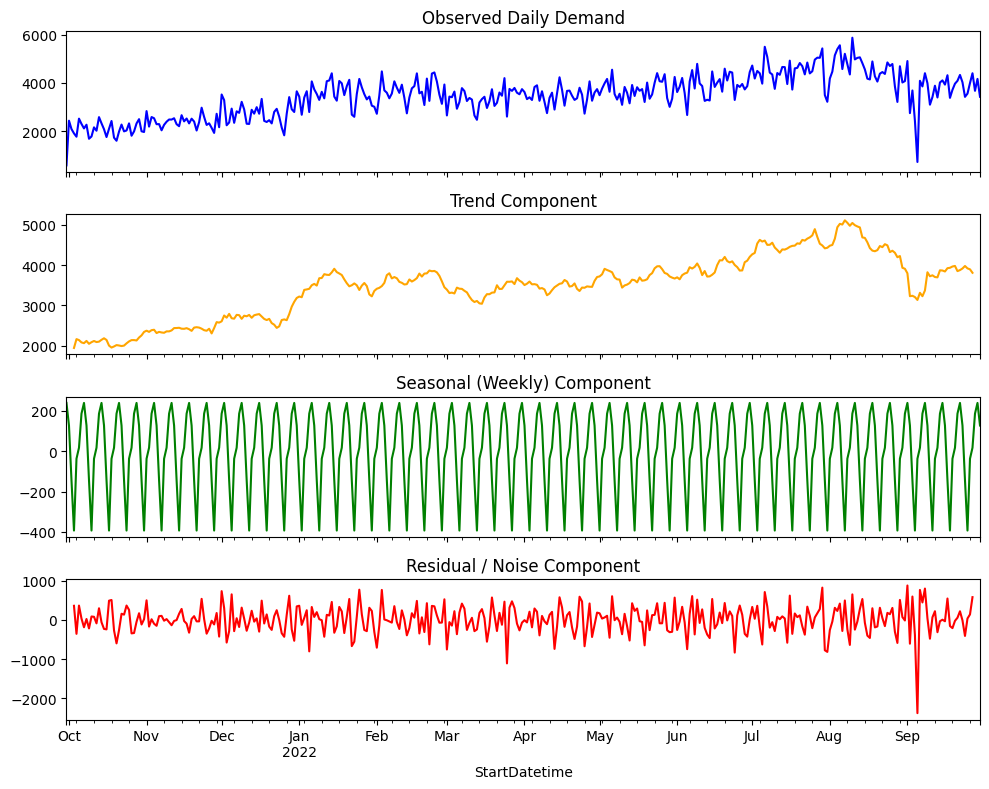

In [3]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Decompose time series
decomposition = seasonal_decompose(daily_demand, model='additive', period=7)
trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid

fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)

decomposition.observed.plot(ax=axes[0], color='blue')
axes[0].set_title('Observed Daily Demand')
decomposition.trend.plot(ax=axes[1], color='orange')
axes[1].set_title('Trend Component')
decomposition.seasonal.plot(ax=axes[2], color='green')
axes[2].set_title('Seasonal (Weekly) Component')
decomposition.resid.plot(ax=axes[3], color='red')
axes[3].set_title('Residual / Noise Component')

plt.tight_layout()
plt.show()

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import numpy as np

# Train-test split (Last 30 days as test)
train = daily_demand.iloc[:-30]
test = daily_demand.iloc[-30:]

# 1. Moving Average Forecast (Window = 7 days)
ma_pred_val = train.rolling(window=7).mean().iloc[-1]
ma_preds = np.full_like(test, ma_pred_val, dtype=float)

# 2. Holt-Winters (Triple Exponential Smoothing) with Weekly Seasonality
hw_model = ExponentialSmoothing(
    train,
    trend='add',
    seasonal='add',
    seasonal_periods=7,
    initialization_method='estimated',
).fit()
hw_preds = hw_model.forecast(len(test))

# Evaluate Performance
ma_mae = mean_absolute_error(test, ma_preds)
ma_rmse = np.sqrt(mean_squared_error(test, ma_preds))

hw_mae = mean_absolute_error(test, hw_preds)
hw_rmse = np.sqrt(mean_squared_error(test, hw_preds))

print(f'Moving Average          -> MAE: {ma_mae:.2f} | RMSE: {ma_rmse:.2f}')
print(f'Holt-Winters (Seasonal) -> MAE: {hw_mae:.2f} | RMSE: {hw_rmse:.2f}')

Moving Average          -> MAE: 581.45 | RMSE: 892.00
Holt-Winters (Seasonal) -> MAE: 719.34 | RMSE: 972.09


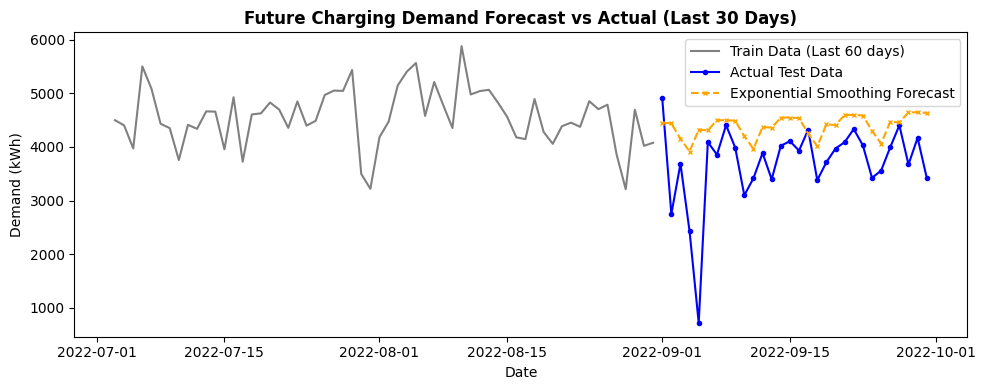

In [5]:
plt.figure(figsize=(10, 4))
plt.plot(train.index[-60:],train.values[-60:],label='Train Data (Last 60 days)',color='gray',)
plt.plot(test.index,test.values,label='Actual Test Data',color='blue',marker='o',markersize=3,)
plt.plot(test.index,hw_preds,label='Exponential Smoothing Forecast',color='orange',linestyle='--',marker='x',markersize=3,)
plt.title('Future Charging Demand Forecast vs Actual (Last 30 Days)', fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Demand (kWh)')
plt.legend()
plt.tight_layout()

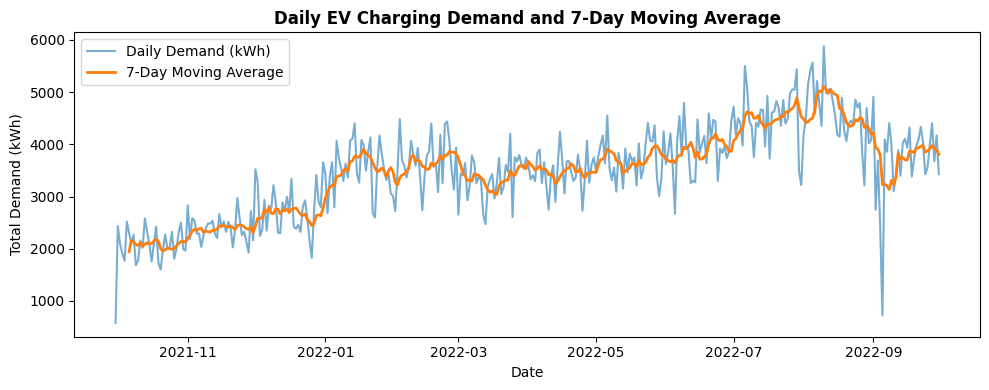

In [6]:
import matplotlib.pyplot as plt

# Plot Daily Demand and 7-Day Moving Average
plt.figure(figsize=(10, 4))
plt.plot(
    daily_demand.index,
    daily_demand.values,
    label='Daily Demand (kWh)',
    color='#1f77b4',
    alpha=0.6,
)
plt.plot(
    daily_demand.index,
    daily_demand.rolling(window=7).mean(),
    label='7-Day Moving Average',
    color='#ff7f0e',
    linewidth=2,
)
plt.title('Daily EV Charging Demand and 7-Day Moving Average', fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Total Demand (kWh)')
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# 1. Fit Holt-Winters Model with weekly seasonality (seasonal_periods=7)
hw_model = ExponentialSmoothing(
    daily_demand,
    trend='add',
    seasonal='add',
    seasonal_periods=7,
    initialization_method='estimated',
).fit()

# 2. Save your fitted holt-winters model using statsmodels' pickle wrapper
from statsmodels.iolib.smpickle import save_pickle
save_pickle(hw_model,r'D:\Sasi\GUVI HCL AI-ML\EV_Charging Project\notebooks\timeseries_holtwinters_model.pkl')

# 3. Forecast next 7 days (will now show unique, day-specific variations!)
future_forecast = hw_model.forecast(steps=7)
print('\nNext 7 Days Dynamic Demand Forecast:')
print(future_forecast)


Next 7 Days Dynamic Demand Forecast:
2022-10-01    3664.529697
2022-10-02    3398.948805
2022-10-03    3722.938939
2022-10-04    3861.598215
2022-10-05    4051.341909
2022-10-06    4136.075344
2022-10-07    3942.622664
Freq: D, dtype: float64


In [8]:
print('Last 7 Days Dynamic Demand Forecast:')
daily_demand.tail(7)

Last 7 Days Dynamic Demand Forecast:


StartDatetime
2022-09-24    3423.92
2022-09-25    3558.89
2022-09-26    3995.26
2022-09-27    4404.18
2022-09-28    3673.44
2022-09-29    4170.49
2022-09-30    3426.66
Freq: D, Name: Demand, dtype: float64